# Decoder-Only, Made Better — Prompting → Fine-Tuning → Your Project
*VietAI NLP Coding Tutorial · single Kaggle T4 (16 GB) · ~45–60 min live*

---

One small model. One question: **how do you actually make a decoder-only model better at a Vietnamese task — and how do you *prove* it moved?**

| Part | Question it answers | What you change | Costs |
|---|---|---|---|
| 1. Prompting | Can words alone lift a weak model? | only the prompt (zero → few → CoT) | inference only |
| 2. Full fine-tuning | Does training beat the best prompt? | the weights (full FT, no LoRA) | one T4, careful knobs |
| 3. Group launchpad | Now do it yourself, on a new task | everything | your call |

Two rules carry through the whole class:
1. **A number decides, not a vibe.** Every change is scored on the same eval set.
2. **"It runs and loss goes down" ≠ "it's correct."** Each part has a place where the code runs, the loss looks fine, and the metric quietly tells you something is wrong. Find it.

## Before you run this notebook

**Kaggle setup:**
1. **Internet ON** — required for model + dataset downloads (Settings → Internet → On).
2. **Accelerator = GPU T4** (Settings → Accelerator → GPU T4). Everything here assumes one T4.
3. Kaggle GPU quota is **30 h/week** — don't leave a session running overnight.

**Runtime budget (rough):** Part 1 ~4–6 min · Part 2 ~6–10 min · Part 3 baseline ~3–5 min per task.
Peak VRAM stays well under 16 GB; only Part 2 (full fine-tuning) needs the careful knobs, and the
memory math there says it fits with headroom.

In [ ]:
# Pin the stack. Do NOT reinstall torch — the Kaggle runtime ships the CUDA build already.
!pip install -q transformers datasets evaluate scikit-learn rouge_score

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.9 MB/s eta 0:00:00


In [ ]:
import os, re, time, random, gc
from collections import Counter

import numpy as np
import torch
import matplotlib.pyplot as plt

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    Trainer,
    TrainingArguments,
    set_seed,
)
from datasets import load_dataset, Dataset
from sklearn.metrics import accuracy_score, f1_score

SEED = 0
set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"   # fixed base model — used in all three parts
print(f"Device: {DEVICE} | Model: {MODEL_NAME}")
if DEVICE != "cuda":
    print("WARNING: no GPU detected. Turn on the T4 (Settings -> Accelerator -> GPU T4).")

Device: cuda | Model: Qwen/Qwen2.5-0.5B-Instruct


## Shared helpers (used by all three parts)

Four small functions, written once and reused everywhere:

- `load_model_and_tokenizer()` — load Qwen in bf16 on the GPU; left-pad for decoding.
- `generate(model, tok, messages, max_new_tokens)` — apply the chat template, decode **only the new tokens**.
- `parse_label(text)` — turn the model's free text into a label id `{0,1,2}`, or `-1` when it can't (a *parse failure*).
- `score(parsed, golds)` — accuracy + F1-macro + **parse-failure rate** on the NLI task.

A decoder-only model does classification by *generating words*, so steps 3–4 (parse + score the text)
are where a surprising amount of your score is silently won or lost. We come back to that in Part 1.

In [ ]:
def load_model_and_tokenizer(model_name=MODEL_NAME):
    """Load Qwen in bf16 on the GPU. Left-padding so a batched decode aligns on the right."""
    tok = AutoTokenizer.from_pretrained(model_name)
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    tok.padding_side = "left"
    model = AutoModelForCausalLM.from_pretrained(model_name, torch_dtype=torch.bfloat16).to(DEVICE)
    model.eval()
    return model, tok


@torch.no_grad()
def generate(model, tok, messages, max_new_tokens=8):
    """Apply the chat template, greedily decode, return ONLY the newly generated text."""
    prompt = tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tok(prompt, return_tensors="pt").to(model.device)
    out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                         pad_token_id=tok.eos_token_id)
    new_tokens = out[0, inputs["input_ids"].shape[1]:]
    return tok.decode(new_tokens, skip_special_tokens=True)


# XNLI labels: 0 = entailment, 1 = neutral, 2 = contradiction.
LABEL_NAMES = {0: "kéo theo", 1: "trung lập", 2: "mâu thuẫn"}
LABEL_KEYS = {
    0: ["kéo theo", "suy ra", "entail"],
    1: ["trung lập", "trung tính", "neutral"],
    2: ["mâu thuẫn", "trái ngược", "contradiction"],
}


def parse_label(text):
    """Robust parser: lower-case, then take the LAST label keyword that appears
    (chain-of-thought puts its conclusion at the end). Returns 0/1/2, or -1 when
    nothing matches — a parse failure is NEVER silently defaulted to a class."""
    t = text.strip().lower()
    best_pos, best_lab = -1, -1
    for lab, keys in LABEL_KEYS.items():
        for k in keys:
            pos = t.rfind(k)
            if pos > best_pos:
                best_pos, best_lab = pos, lab
    return best_lab


def score(parsed, golds):
    """accuracy + F1-macro + parse-failure rate. Parse failures (-1) count as wrong."""
    n = len(parsed)
    fails = sum(1 for p in parsed if p == -1)
    preds = [p if p != -1 else 99 for p in parsed]   # 99 matches no gold label -> counts as wrong
    return {
        "accuracy": accuracy_score(golds, preds),
        "f1_macro": f1_score(golds, preds, average="macro", labels=[0, 1, 2]),
        "parse_fail": fails / n,
    }

# Part 1 — Prompting (we never touch the weights)

**Anchor question:** *We never change a single weight. Can changing only the words we send lift a small,
mediocre model on a Vietnamese **reasoning** task — and how do we prove it moved?*

**Task: Vietnamese NLI (XNLI, `vi`).** Given a *premise* and a *hypothesis*, decide the relationship:
**kéo theo** (entailment), **trung lập** (neutral), or **mâu thuẫn** (contradiction). This is a genuine
reasoning task — which is exactly why chain-of-thought has something to earn here.

The arc: **zero-shot → few-shot → chain-of-thought**, each scored on the *same* eval set with
**accuracy + F1-macro + parse-failure rate**.

In [ ]:
# Load XNLI (Vietnamese). Eval on the validation split — it is human-translated, so cleaner.
xnli = load_dataset("facebook/xnli", "vi")
print(xnli)

N_EVAL = 75    # small for a quick class run; raise for tighter numbers
eval_rows = xnli["validation"].shuffle(seed=SEED).select(range(N_EVAL))
golds = list(eval_rows["label"])
print("\nEval label distribution:", dict(Counter(golds)),
      "  (roughly balanced -> the metric story here is PARSE FAILURES, not class imbalance)")

# A tiny BALANCED few-shot pool from the TRAIN split (2 examples per label).
train_shuf   = xnli["train"].shuffle(seed=SEED)
fewshot_pool = (
    train_shuf.filter(lambda x: x["label"] == 0).select(range(2)).to_list() +
    train_shuf.filter(lambda x: x["label"] == 1).select(range(2)).to_list() +
    train_shuf.filter(lambda x: x["label"] == 2).select(range(2)).to_list()
)
print(f"Few-shot pool: {len(fewshot_pool)} examples (2 per label)")

README.md:   0%|          | 0.00/20.8k [00:00<?, ?B/s]

vi/train-00000-of-00001.parquet:   0%|          | 0.00/57.1M [00:00<?, ?B/s]

vi/test-00000-of-00001.parquet:   0%|          | 0.00/364k [00:00<?, ?B/s]

vi/validation-00000-of-00001.parquet:   0%|          | 0.00/186k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/392702 [00:00<?, ? examples/s]

...

DatasetDict({
    train: Dataset({
        features: ['premise', 'hypothesis', 'label'],
        num_rows: 392702
    })
    test: Dataset({
        features: ['premise', 'hypothesis', 'label'],
        num_rows: 5010
    })
    validation: Dataset({
        features: ['premise', 'hypothesis', 'label'],
        num_rows: 2490
    })
})

Eval label distribution: {2: 29, 1: 27, 0: 19}   (roughly balanced -> the metric story here is PARSE FAILURES, not class imbalance)


Filter:   0%|          | 0/392702 [00:00<?, ? examples/s]

Filter:   0%|          | 0/392702 [00:00<?, ? examples/s]

Filter:   0%|          | 0/392702 [00:00<?, ? examples/s]

Few-shot pool: 6 examples (2 per label)


In [ ]:
# The prompt builders. Zero-shot is deliberately minimal -> a weak baseline near chance (that is the headroom).
SYS = "Bạn là trợ lý phân tích quan hệ logic giữa hai câu tiếng Việt."

def user_prompt(premise, hypothesis):
    return (f"Tiền đề: {premise}\n"
            f"Giả thuyết: {hypothesis}\n"
            f'Quan hệ giữa hai câu là "kéo theo", "trung lập", hay "mâu thuẫn"?')

def zero_messages(ex):
    return [{"role": "system", "content": SYS},
            {"role": "user", "content": user_prompt(ex["premise"], ex["hypothesis"]) + " Trả lời bằng MỘT từ."}]

def run_condition(model, tok, rows, build_messages, max_new_tokens):
    """Generate a raw output string for every eval row. Parsing happens separately on purpose
    (Part 1 re-parses the SAME zero-shot outputs two different ways to expose the parser gotcha)."""
    return [generate(model, tok, build_messages(ex), max_new_tokens=max_new_tokens) for ex in rows]

In [ ]:
# Load the model once (reused through Parts 1-2) and run the zero-shot condition.
model, tok = load_model_and_tokenizer()

t0 = time.time()
raw_zero = run_condition(model, tok, eval_rows, zero_messages, max_new_tokens=8)
lat_zero = time.time() - t0

print(f"Zero-shot done in {lat_zero:.1f}s. A few raw outputs:")
for r in raw_zero[:6]:
    print("   ", repr(r))

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Zero-shot done in 28.4s. A few raw outputs:
    'Trung lập'
    'Kéo theo'
    'Trung lập'
    'Kéo theo'
    'Kéo theo'
    'Kéo theo'


### The decoder-only classification gotcha (taught, not hidden)

The model didn't return a clean label — it returned *text*. So we have to **parse** it. Watch what the
parser choice does to the score, using the **exact same** zero-shot outputs.

- A **naive** parser checks for an exact string and quietly sends anything it doesn't recognise to one
  class. Its parse-failure rate looks like **0%** — because it never admits failure. It just inflates one
  class and caps your real score.
- A **robust** parser normalises the text, substring-matches, and returns `-1` when it truly can't tell —
  so failures are *counted*, not hidden.

This is why we track **parse-failure rate** as a first-class metric. (Chain-of-thought, with its long
outputs, stresses the parser the most — keep an eye on it later.)

In [ ]:
def parse_label_naive(text):
    """A first-attempt parser: exact match, no normalisation, unknown -> class 0 (silently)."""
    mapping = {"kéo theo": 0, "trung lập": 1, "mâu thuẫn": 2}
    return mapping.get(text, 0)   # <- the gotcha: every unparseable output becomes "entailment"

naive  = [parse_label_naive(r) for r in raw_zero]
robust = [parse_label(r)       for r in raw_zero]

print("NAIVE  parser:", score(naive, golds))
print("   predicted class counts:", dict(Counter(naive)),
      "<- notice one class is wildly inflated, and parse_fail reads 0.0 (hidden)")
print()
print("ROBUST parser:", score(robust, golds))
print("   predicted class counts:", dict(Counter(robust)),
      "<- now the true parse-failure rate is visible")

NAIVE  parser: {'accuracy': 0.25333333333333335, 'f1_macro': 0.1347517730496454, 'parse_fail': 0.0}
   predicted class counts: {0: 75} <- notice one class is wildly inflated, and parse_fail reads 0.0 (hidden)

ROBUST parser: {'accuracy': 0.32, 'f1_macro': 0.27380857876213915, 'parse_fail': 0.013333333333333334}
   predicted class counts: {1: 12, 0: 57, 2: 5, -1: 1} <- now the true parse-failure rate is visible


### Few-shot — anchor the 3 labels and the output format

We prepend `k` labelled premise/hypothesis examples. `FEWSHOT_K = 2` is a **starting point**, not a
recommendation — raising it is one of the first things you should try. Few-shot mainly teaches the model
the *format* (one of three words), which usually cuts parse failures and nudges accuracy up.

In [ ]:
FEWSHOT_K = 2   # de-tuned starting point — try raising it

def fewshot_messages(ex):
    msgs = [{"role": "system", "content": SYS}]
    for shot in fewshot_pool[:FEWSHOT_K]:
        msgs.append({"role": "user",
                     "content": user_prompt(shot["premise"], shot["hypothesis"]) + " Trả lời bằng MỘT từ."})
        msgs.append({"role": "assistant", "content": LABEL_NAMES[shot["label"]]})
    msgs.append({"role": "user",
                 "content": user_prompt(ex["premise"], ex["hypothesis"]) + " Trả lời bằng MỘT từ."})
    return msgs

t0 = time.time()
raw_few = run_condition(model, tok, eval_rows, fewshot_messages, max_new_tokens=8)
lat_few = time.time() - t0
few_parsed = [parse_label(r) for r in raw_few]
print(f"Few-shot (k={FEWSHOT_K}) done in {lat_few:.1f}s:", score(few_parsed, golds))

Few-shot (k=2) done in 18.4s: {'accuracy': 0.3466666666666667, 'f1_macro': 0.3382716049382715, 'parse_fail': 0.0}


### Chain-of-thought — let it reason, then conclude

NLI is a *reasoning* task: the answer depends on the relationship between two sentences, not a surface
keyword. So we ask the model to reason in one sentence and then end with an explicit label line. CoT needs
a bigger `max_new_tokens` (it writes more), and the parser must pick out the **final** label — which is
exactly what our robust `parse_label` does. Whether CoT actually helps is, as always, decided by the number.

In [ ]:
def cot_messages(ex):
    instr = ('\nGiải thích quan hệ giữa hai câu trong MỘT câu ngắn gọn không quá 20 từ, '
             'rồi kết luận ở dòng cuối đúng dạng: "Nhãn: kéo theo | trung lập | mâu thuẫn".')
    return [{"role": "system", "content": SYS},
            {"role": "user", "content": user_prompt(ex["premise"], ex["hypothesis"]) + instr}]

COT_MAX_NEW = 168
t0 = time.time()
raw_cot = run_condition(model, tok, eval_rows, cot_messages, max_new_tokens=COT_MAX_NEW)
lat_cot = time.time() - t0
assert len(raw_cot) == len(golds), (
    f"Length mismatch: {len(raw_cot)} CoT outputs vs {len(golds)} gold labels. "
    "Re-run all cells from the data cell downward in order.")
cot_parsed = [parse_label(r) for r in raw_cot]
print(f"CoT done in {lat_cot:.1f}s:", score(cot_parsed, golds))
print("\nExample CoT output:\n", raw_cot[0])

CoT done in 392.1s: {'accuracy': 0.28, 'f1_macro': 0.21661375661375662, 'parse_fail': 0.05333333333333334}

Example CoT output:
 Trong câu hỏi này, chúng ta có thể thấy rằng hai câu đều liên quan đến vấn đề về việc trẻ mầm non bị viêm tai giữa. Tuy nhiên, hai câu khác nhau về nguyên nhân gây ra viêm tai giữa.

Câu thứ nhất nói về nguyên nhân phổ biến nhất là viêm tai giữa hoặc nhiễm trùng tai giữa lặp đi lặp lại. Câu thứ hai chỉ nhắc đến viêm tai giữa là vô cùng hiếm gặp trong những năm học mầm non của trẻ.

Vì vậy, câu trả lời chính xác là "kéo theo" vì cả hai câu đều liên quan đến vấn đề viêm tai giữa, nhưng một trong hai câu đưa ra thông tin cụ thể hơn về nguyên nhân gây ra viêm tai giữa.

Đối với câu kết luận, câu thứ nhất sẽ là "Vi


condition     acc     f1  parsefail   lat(s)
zero-shot   0.320  0.274      0.013     28.4
few-shot    0.347  0.338      0.000     18.4
CoT         0.280  0.217      0.053    392.1


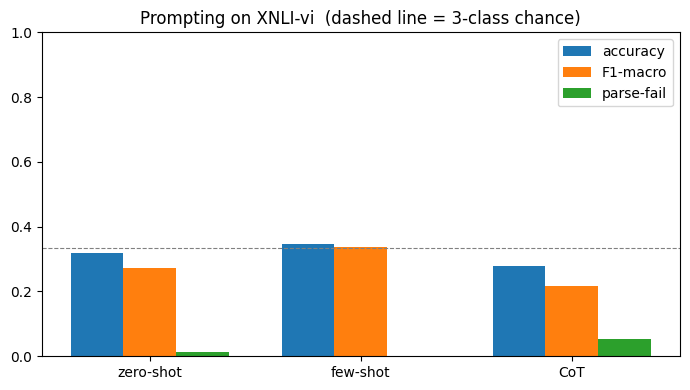

In [ ]:
# Pull the three conditions into one table + chart. (All use the ROBUST parser.)
results = {
    "zero-shot": {**score(robust,     golds), "latency_s": lat_zero},
    "few-shot":  {**score(few_parsed, golds), "latency_s": lat_few},
    "CoT":       {**score(cot_parsed, golds), "latency_s": lat_cot},
}

print(f"{'condition':<10} {'acc':>6} {'f1':>6} {'parsefail':>10} {'lat(s)':>8}")
for k, v in results.items():
    print(f"{k:<10} {v['accuracy']:>6.3f} {v['f1_macro']:>6.3f} {v['parse_fail']:>10.3f} {v['latency_s']:>8.1f}")

conds = list(results)
x = np.arange(len(conds)); w = 0.25
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(x - w, [results[c]["accuracy"]   for c in conds], w, label="accuracy")
ax.bar(x,     [results[c]["f1_macro"]   for c in conds], w, label="F1-macro")
ax.bar(x + w, [results[c]["parse_fail"] for c in conds], w, label="parse-fail")
ax.axhline(1/3, ls="--", c="gray", lw=0.8)   # 3-class chance
ax.set_xticks(x); ax.set_xticklabels(conds); ax.set_ylim(0, 1)
ax.set_title("Prompting on XNLI-vi  (dashed line = 3-class chance)")
ax.legend(); plt.tight_layout(); plt.show()

### Where prompting leaves us (open hypotheses, not a checklist)

You moved a number with words alone. Now sit with what the chart says and form hypotheses **before**
Part 2:

- Did few-shot help mostly by cutting **parse failures**, or by genuinely raising accuracy? (Look at both
  columns.) If it was mostly parsing, what does that tell you about the zero-shot "baseline"?
- Did CoT actually beat few-shot on **F1-macro**, or did it just spend latency? On which label does it help
  most — and does that match "this is a reasoning task"?
- Prompting changes the *input*, never the *weights*. That is its ceiling. What would it take to move the
  weights toward this task — and would it be worth it? That is Part 2.

# Part 2 — Full fine-tuning (the brute-force way, no LoRA)

**Anchor question:** *Prompting plateaued. If we fine-tune **all** the weights on the same task, how much
better than the best prompt do we get — and what is the catch on 16 GB?*

We stay on the **same task** (XNLI `vi`) and evaluate on the **same** eval rows, so the payoff chart
extends Part 1 directly.

### Reveal: this is just SFT (teacher forcing) on `(prompt, label-word)` pairs

Full fine-tuning a decoder-only model on `(prompt, answer)` pairs *is* supervised fine-tuning — the same
teacher-forcing loop you have seen before. We feed the chat-formatted prompt followed by the gold label
word, and train the model to produce that word.

| Generic teacher forcing | Our NLI SFT |
|---|---|
| feed gold prefix, predict next token | feed the chat prompt, predict the label word |
| cross-entropy over target tokens | cross-entropy over the label-word tokens |
| `loss = model(input_ids, labels=...).loss` | identical — the work is all in building `labels` |

That last row is the whole game in Part 2: **what goes into `labels` decides what the model learns.**

In [ ]:
# Build a small BALANCED train subset from the XNLI train split (machine-translated — fine for training).
N_PER_LABEL = 300   # 300 per label = 900 total
train_shuf  = xnli["train"].shuffle(seed=SEED)
train_rows  = (
    train_shuf.filter(lambda x: x["label"] == 0).select(range(N_PER_LABEL)).to_list() +
    train_shuf.filter(lambda x: x["label"] == 1).select(range(N_PER_LABEL)).to_list() +
    train_shuf.filter(lambda x: x["label"] == 2).select(range(N_PER_LABEL)).to_list()
)
random.shuffle(train_rows)
print("Train label distribution:", dict(Counter(r["label"] for r in train_rows)))

def to_example(r):
    """Format with the SAME prompt template as Part 1, then append the gold label word + EOS."""
    msgs = [{"role": "system", "content": SYS},
            {"role": "user", "content": user_prompt(r["premise"], r["hypothesis"]) + " Trả lời bằng MỘT từ."}]
    prompt_text = tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    full_text = prompt_text + LABEL_NAMES[r["label"]] + tok.eos_token
    return {"prompt_text": prompt_text, "full_text": full_text}

train_ds = Dataset.from_list([to_example(r) for r in train_rows])
print("\nOne formatted example (tail):\n ...", train_ds[0]["full_text"][-90:])

Train label distribution: {1: 300, 2: 300, 0: 300}

One formatted example (tail):
 ...  hay "mâu thuẫn"? Trả lời bằng MỘT từ.<|im_end|>
<|im_start|>assistant
trung lập<|im_end|>


### The SFT collator

`Trainer` shifts `input_ids`/`labels` internally, so all we owe it is a correct `labels` tensor:
`-100` everywhere we do **not** want a loss, the real token id everywhere we do. Padding is masked below.
Read the `labels` line carefully before you run training — Part 2's bug lives in this cell.

In [ ]:
class NLICollator:
    """Pad a batch of (prompt, full) examples and build the labels for SFT."""
    def __init__(self, tok, max_length=128):
        self.tok = tok
        self.max_length = max_length

    def __call__(self, batch):
        input_ids, labels, attn = [], [], []
        for b in batch:
            ids = self.tok(b["full_text"], truncation=True, max_length=self.max_length)["input_ids"]
            input_ids.append(ids)
            labels.append(list(ids))           # targets = a copy of the inputs
            attn.append([1] * len(ids))
        maxlen = max(len(x) for x in input_ids)
        pad_id = self.tok.pad_token_id
        for i in range(len(input_ids)):
            d = maxlen - len(input_ids[i])
            input_ids[i] = input_ids[i] + [pad_id] * d
            labels[i]    = labels[i]    + [-100]  * d   # ignore padding in the loss
            attn[i]      = attn[i]      + [0]     * d
        return {"input_ids": torch.tensor(input_ids),
                "attention_mask": torch.tensor(attn),
                "labels": torch.tensor(labels)}

### Train — de-tuned "starting point" knobs that fit a T4

These knobs are conservative on purpose (a starting point you can push), and chosen so full fine-tuning
fits 16 GB:

- `epochs=1`, `lr=2e-5`, `max_length=128`, `batch=2`, `grad_accum=8` (effective batch 16)
- `bf16=True`, `gradient_checkpointing=True`

**Memory math:** 0.5B params in bf16 (~1 GB) + bf16 grads (~1 GB) + AdamW fp32 moments (~4 GB) + small
checkpointed activations ≈ **8–11 GB**. Fits with headroom. The honest catch: full FT tops out near
0.5–0.7B *because of those optimizer states* — which is the exact pain LoRA later removes.

In [ ]:
# Reuse the Part-1 model object: train it in place, then evaluate the SAME weights.
args = TrainingArguments(
    output_dir="/tmp/nli_sft",
    num_train_epochs=1,
    per_device_train_batch_size=2,
    gradient_accumulation_steps=8,
    learning_rate=2e-5,
    bf16=True,
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    logging_steps=10,
    report_to="none",
    remove_unused_columns=False,   # keep our string columns so the collator can see them
)
trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    data_collator=NLICollator(tok, max_length=128),
)
trainer.train()
print("Fine-tuning complete — the loss should have fallen.")

Step,Training Loss
10,2.037958
20,1.419717
30,1.385608
40,1.357450
50,1.353069


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Fine-tuning complete — the loss should have fallen.


In [ ]:
# Put the model back in inference mode and score it on the SAME eval rows as Part 1.
model.config.use_cache = True
model.gradient_checkpointing_disable()
model.eval()

raw_ft = run_condition(model, tok, eval_rows, zero_messages, max_new_tokens=8)
ft_parsed = [parse_label(r) for r in raw_ft]
ft_score = score(ft_parsed, golds)

best_prompt_f1 = max(results[c]["f1_macro"] for c in results)
print("Fine-tuned (same minimal prompt):", ft_score)
print(f"Best prompting F1-macro (Part 1): {best_prompt_f1:.3f}")
print(f"Fine-tuned   F1-macro          : {ft_score['f1_macro']:.3f}")

Fine-tuned (same minimal prompt): {'accuracy': 0.5466666666666666, 'f1_macro': 0.5583694083694084, 'parse_fail': 0.0}
Best prompting F1-macro (Part 1): 0.338
Fine-tuned   F1-macro          : 0.558


### Stop — loss went down, but did the metric move?

If the fine-tuned F1-macro is barely above your **few-shot** number, something is wrong even though
training "worked" and the loss curve looked healthy. Debug together:

- The loss is an average over **every supervised token**. Which tokens did we supervise?
- Print one `labels` row from the collator. How many entries are `-100`? Where are the *real* targets?
- If the prompt tokens are also targets, the model spends almost all its loss learning to **re-type the
  prompt** — the one label word at the end is a rounding error in the average. Loss falls (the prompt is
  easy to copy), but the model never specialised on the *decision*.

**The fix** is one block in `NLICollator`: mask the prompt span so the loss is computed only on the label
word. Apply it, re-run training + eval, and watch F1 jump past the best prompt. (This is the exact
`labels[:, :prompt_len] = -100` move that every SFT recipe makes.)

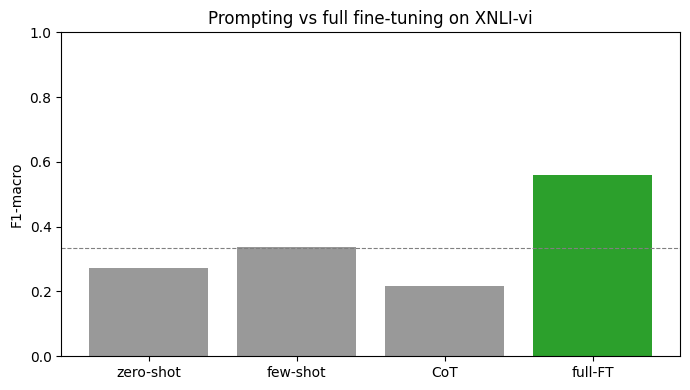

With the prompt span masked, full-FT should clear the best prompt. If it doesn't, re-read the bug cell.


In [ ]:
# Payoff chart — extends Part 1 with the fine-tuned bar.
labels_bar = list(results) + ["full-FT"]
f1s = [results[c]["f1_macro"] for c in results] + [ft_score["f1_macro"]]
plt.figure(figsize=(7, 4))
plt.bar(labels_bar, f1s, color=["#999", "#999", "#999", "#2ca02c"])
plt.axhline(1/3, ls="--", c="gray", lw=0.8)
plt.ylabel("F1-macro"); plt.ylim(0, 1)
plt.title("Prompting vs full fine-tuning on XNLI-vi")
plt.tight_layout(); plt.show()
print("With the prompt span masked, full-FT should clear the best prompt. If it doesn't, re-read the bug cell.")

# Part 3 — Group project launchpad

You know how to prompt and how to fine-tune. Now your group picks **one** task, keeps the **same base
model** (`Qwen/Qwen2.5-0.5B-Instruct`), pushes a metric as far as you can, and presents *what you tried
and what the numbers said.*

> **This is a starting line, not a finish line. "Run All" is not a strategy.** This launchpad gives you a
> correct-enough scaffold and one intentionally weak baseline per task. At least one default in here is
> wrong for some tasks — find it through error analysis, not by guessing.

Set `TASK` below to your group's task. Everything downstream dispatches on it, so the scaffold is identical
for every group.

In [ ]:
TASK = "classification"   # <- your group sets this: "classification" | "summarization" | "qa"

# Shared decoding budget for the baseline, used by EVERY task below.
MAX_NEW_TOKENS = 8        # one number for all three tasks — is that right for each of them?

In [ ]:
# Reload the FIXED base model — groups start fresh, not from the NLI-fine-tuned weights.
del model; gc.collect()
if DEVICE == "cuda":
    torch.cuda.empty_cache()
model, tok = load_model_and_tokenizer()

SYS_VI = "Bạn là trợ lý tiếng Việt."

if TASK == "classification":
    # Vietnamese app/product reviews: 0 = negative, 1 = positive.
    raw_ds = load_dataset("sepidmnorozy/Vietnamese_sentiment")["validation"]
    data   = raw_ds.shuffle(seed=SEED).select(range(min(75, len(raw_ds))))
    golds  = list(data["label"])
    def make_prompt(ex):
        return [{"role": "system", "content": SYS_VI},
                {"role": "user",   "content": f'Đánh giá: {ex["text"]}\nCảm xúc là "tiêu cực" hay "tích cực"? (một từ)'}]
    print("label distribution:", dict(Counter(golds)), "  (0=negative, 1=positive)")

elif TASK == "summarization":
    # Vietnamese news: 'content' = article, 'summary' = target.
    raw_ds = load_dataset("vietgpt/news_summarization_vi", split="test")
    data   = raw_ds.shuffle(seed=SEED).select(range(75))
    def make_prompt(ex):
        return [{"role": "system", "content": SYS_VI},
                {"role": "user",   "content": f'Tóm tắt đoạn văn sau trong một câu ngắn:\n{ex["content"][:1200]}'}]
    print(f"{len(data)} news articles loaded.")

elif TASK == "qa":
    # XQuAD Vietnamese: extractive QA, SQuAD format.
    raw_ds = load_dataset("google/xquad", "xquad.vi")["validation"]
    data   = raw_ds.shuffle(seed=SEED).select(range(75))
    def make_prompt(ex):
        return [{"role": "system", "content": SYS_VI},
                {"role": "user",   "content": f'Đoạn văn: {ex["context"]}\nCâu hỏi: {ex["question"]}\nTrả lời ngắn, trích từ đoạn văn:'}]
    print("Example Q:", data[0]["question"], "-> A:", data[0]["answers"]["text"])

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

train.csv:   0%|          | 0.00/329k [00:00<?, ?B/s]

dev.csv:   0%|          | 0.00/52.0k [00:00<?, ?B/s]

test.csv:   0%|          | 0.00/99.2k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/2384 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/331 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/685 [00:00<?, ? examples/s]

label distribution: {0: 42, 1: 33}   (0=negative, 1=positive)


In [ ]:
# Baseline: zero-shot, greedy, the shared MAX_NEW_TOKENS. One intentionally weak number.
t0 = time.time()
raw_preds = [generate(model, tok, make_prompt(data[i]), max_new_tokens=MAX_NEW_TOKENS)
             for i in range(len(data))]
print(f"{len(raw_preds)} outputs in {time.time()-t0:.0f}s.  Sample outputs:")
for r in raw_preds[:4]:
    print("   ", repr(r[:100]))

# Score the baseline — one branch per task.
if TASK == "classification":
    SENT_KEYS = {0: ["tiêu cực", "negative"], 1: ["tích cực", "positive"]}
    def parse_sentiment(text):
        t, best_pos, best_lab = text.strip().lower(), -1, -1
        for lab, keys in SENT_KEYS.items():
            for k in keys:
                pos = t.rfind(k)
                if pos > best_pos:
                    best_pos, best_lab = pos, lab
        return best_lab
    preds = [parse_sentiment(r) for r in raw_preds]
    safe  = [p if p != -1 else 99 for p in preds]
    print("baseline:", {"f1_macro":   round(f1_score(golds, safe, average="macro", labels=[0,1]), 4),
                        "parse_fail": round(sum(p == -1 for p in preds) / len(preds), 4)})

elif TASK == "summarization":
    from rouge_score import rouge_scorer as _rs
    scorer = _rs.RougeScorer(["rougeL"], use_stemmer=False)
    rouges = [scorer.score(data[i]["summary"], raw_preds[i])["rougeL"].fmeasure for i in range(len(data))]
    print("baseline ROUGE-L:", round(sum(rouges) / len(rouges), 4))
    print("(ROUGE-L on Vietnamese uses whitespace tokens = syllables; trust relative changes, not absolutes)")

elif TASK == "qa":
    def token_f1(pred, gold_answers):
        p_toks = pred.lower().split()
        best = 0.0
        for g in gold_answers:
            g_toks = g.lower().split()
            common = sum((Counter(p_toks) & Counter(g_toks)).values())
            if common and p_toks and g_toks:
                prec, rec = common / len(p_toks), common / len(g_toks)
                best = max(best, 2 * prec * rec / (prec + rec))
        return best
    f1s = [token_f1(raw_preds[i], data[i]["answers"]["text"]) for i in range(len(data))]
    print("baseline token-F1:", round(sum(f1s) / len(f1s), 4))

75 outputs in 15s.  Sample outputs:
    'Tích cực'
    'Tích cực. Bạn đã đánh giá'
    'Tích cực.'
    'Tích cực'
baseline: {'f1_macro': 0.4511, 'parse_fail': 0.0533}


### Open hypotheses (no recipe — these are questions, not answers)

Work the loop: **measure on your local val split → read the errors → form a hypothesis → test it → let the
number decide.** For each direction below, write down *why it might help*, *how you'd test it*, and *what
number would tell you it worked.*

- **Decoding.** Look hard at the raw baseline outputs above. Is the model being cut off mid-thought? Are
  short labels surviving but long answers truncating? What single shared setting would explain that across
  tasks — and what happens to the metric when you change it? *(Start here. A default in the scaffold is
  wrong for some tasks.)*
- **Prompting (from Part 1).** Does few-shot or chain-of-thought help *this* task? Reasoning-heavy tasks
  gained from CoT on NLI — is yours reasoning-heavy?
- **Fine-tuning (from Part 2).** Could you SFT on `(input, target)` pairs the way Part 2 did? What is your
  `target`, and what would the `labels` mask look like for *your* task? (Part 2's NLI fine-tune is a
  *starting point to adapt*, not a result to copy — it was a different task.)
- **Data.** What public Vietnamese data exists for your task? More data, cleaner data, or a different split?
- **Metric honesty.** Does your metric reward the right thing? (ROUGE rewards n-gram overlap; token-F1 is
  softer than EM; F1-macro treats both classes equally even if one is harder.) Where does your metric lie,
  and what would you add to tell the fuller story?

### What to present (rubric)

Five minutes per group. Show:

1. **Baseline → improved** number on the *same* local eval split (the delta is the story).
2. **One ablation** — a single change, with the number before and after, isolated.
3. **One error-analysis finding** — a concrete failure pattern you read off real outputs, and what you did
   about it.
4. **Honest metric discussion** — what your metric does and does not capture, and one number you'd add to
   tell the fuller story.

No leaderboard theatre. A small, *honest*, well-explained gain beats a big number you can't account for.